# Full comparison of Parameterizations
Author: Anne Hermann

In [1]:
import sys
sys.path.append('../')
sys.path.append('../../')

import jax.numpy as jnp
import utils.petrophysic as petro
import utils.petrophysics_capillaryBundles as petro_cap
import matplotlib.pyplot as plt
import utils.parameter_interpolation as inter
import cmocean.cm as cmo

In [2]:
param = "cap"
interp_folder = "../../input/interpolation/"
interp_filename = f"interpolation_{param}.pkl"

In [3]:
soil = jnp.ones((40,400))  # soil type array

# # Sandy soil parameters
soil_type = {1:{}, 2:{}}
soil_type[1]["alpha"] = 14.5                        # van Genuchten alpha [1/m]
soil_type[1]["Ksat"] = 8.25e-5                      # saturated hydraulic conductivity [m/s]
soil_type[1]["N"] = 2.68                            # van Genuchten N [-]
soil_type[1]["Theta_r"] = 0.045                     # minimum volumetric water content [-]
soil_type[1]["Theta_s"] = 0.43                      # maximum volumetric water content [-]

# # Loamy soil parameters
soil_type[2]["alpha"] = 1.6
soil_type[2]["Ksat"] = 6.94e-7
soil_type[2]["N"] = 1.37
soil_type[2]["Theta_r"] = 0.034
soil_type[2]["Theta_s"] = 0.46

In [4]:
# discretize S -> hc
Se = jnp.linspace(0,1,int(5e4)) # effective saturation [-]
#   discretize T
T = jnp.append(jnp.append(jnp.arange(-30,-0.15,.1),jnp.arange(-0.15,0,1e-3)),jnp.arange(0,10,1)) # K
# interpolate krel and theta_l for each soil type
#soil_type = inter.interpolate_parameter_drying(Se, T, soil_type, filename=interp_folder+interp_filename_drying, method='monotonic', extrapolate=True)
soil_type = inter.interpolate_parameter(Se, T, soil_type, filename=interp_folder+interp_filename, parametrization=param, method='monotonic', extrapolate=True)

del T,Se

Loaded interpolated soil type from file:  ../../input/interpolation/interpolation_cap.pkl


In [5]:
plt.rcParams.update({'font.size': 12})
cm = 1/2.54  # centimeters in inches

In [6]:
Se = jnp.linspace(1e-3,1,1000)
#Se = jnp.linspace(1e-3,1,100)
hc = petro_cap.h_from_S(Se, soil_type[1]["alpha"], soil_type[1]["N"])
T = jnp.linspace(-10,10,10000)

# X,Y = jnp.meshgrid(hc, T)
# Z = soil_type[1]["theta_l_interp"](X.flatten(), Y.flatten()).reshape(X.shape)

# fig = plt.figure(figsize=(20*cm,20*cm))
# ax = fig.add_subplot(111, projection="3d")
# ax.view_init(elev=10, azim=-20, roll=0)
# ax.plot_surface(jnp.log10(X), Y, Z, cmap=cmo.ice_r)
# ax.set_xlabel(r'$h_c$ [m]')
# ax.set_ylabel(r'$T$ [°C]')
# ax.set_zlabel(r'$\theta_l$ [-]')
# plt.tight_layout()
# plt.savefig(f"theta_l_{param}.pdf", dpi=600, bbox_inches='tight', pad_inches=0.5)

/tmp/ipykernel_264264/2407919381.py:66: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


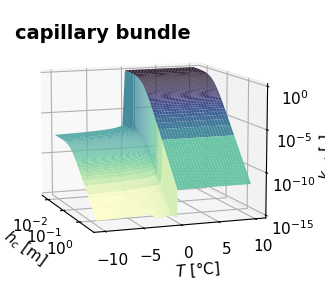

In [7]:
plt.rcParams.update({'font.size': 11})
cm = 1/2.54  # centimeters in inches

X,Y = jnp.meshgrid(hc, T)
Z = soil_type[1]["k_rel_interp"](X.flatten(), Y.flatten()).reshape(X.shape)
Z = jnp.log10(Z)
fig, ax = plt.subplots(figsize=(9*cm,9*cm),subplot_kw={"projection": "3d"})
Z = Z.at[jnp.where(Z<-15)].set(jnp.nan)
ax.view_init(elev=10, azim=-20, roll=0)
ax.plot_surface(jnp.log10(X),Y,Z, cmap=cmo.deep)
ax.set_xticks([-2,-1,0])
ax.set_xticklabels([f'$10^{{{i}}}$' for i in range(-2,1)])
ax.set_zticks([-15, -10, -5, 0])
ax.set_zticklabels([f'$10^{{{i}}}$' for i in range(-15,5,5)])
# ax.set_zlim(-15,0)
ax.set_xlabel(r'$h_c$ [m]')
ax.set_ylabel(r'$T$ [°C]')
ax.set_zlabel(r'$k_{rel}$ [-]')
if param == "cap":
    ax.text2D(
        0.02, 0.95, "capillary bundle",
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top"
    )
if param == "drying":
    ax.text2D(
        0.02, 0.95, "drying",
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top"
    )
if param == "permaFoam_omega10":
    ax.text2D(
        0.02, 0.95, r"impedance, $\Omega=10$",
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top"
    )
if param == "permaFoam_omega50":
    ax.text2D(
        0.02, 0.95, r"impedance, $\Omega=50$",
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top"
    )   
    
if param == "drying_omega10":
    ax.text2D(
        0.02, 0.95, r"drying, $\Omega=10$",
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top"
    )        
#ax.text(0.5, 0.5, 120, 'C', transform=ax.transAxes, fontsize=14, color='k', ha='center', va='center', rotation=30)
fig.tight_layout()
fig.savefig(f"k_rel_{param}.pdf", dpi=600, bbox_inches='tight', pad_inches=0.5)